# Практична робота 8.2
## Нейронні мережі в розпізнаванні образів. Частина 2

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Conv2D, Dense, Flatten, Dropout, MaxPooling2D
from tensorflow.keras.callbacks import EarlyStopping

seed = 1234578790
tf.keras.utils.set_random_seed(seed)

### 1. Перегляд даних
Fashion MNIST містить зображення одягу та взуття десяти класів. Кожне зображення має розмір 28 × 28 пікселів і один колірний канал.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train set:    60000 samples
Test set:     10000 samples
Sample dims:  (60000, 28, 28)


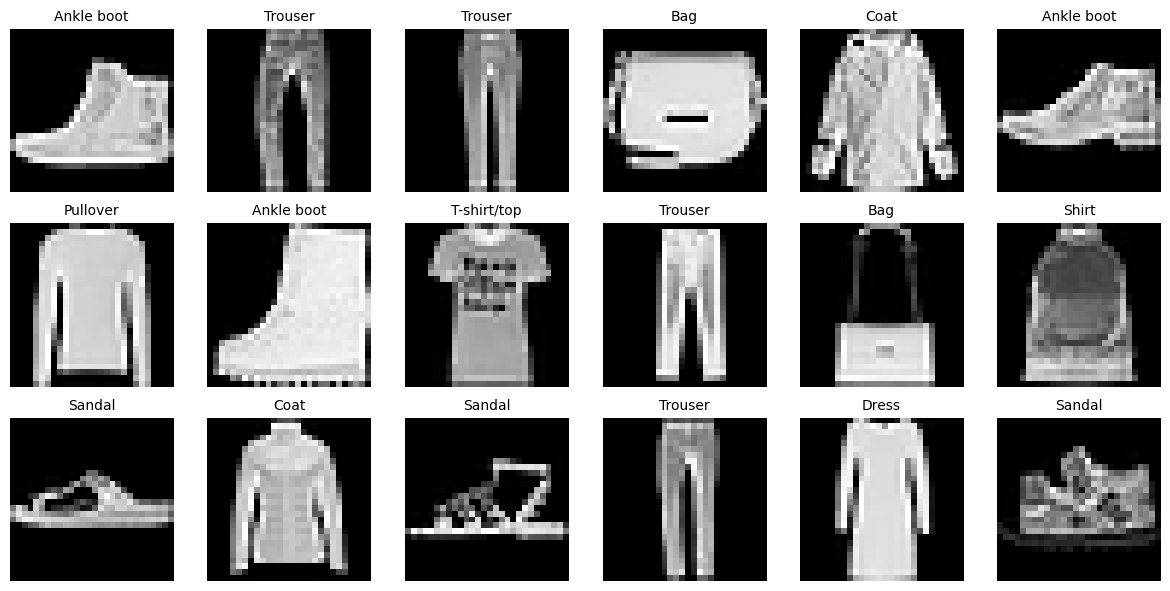

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print('Train set:   ', len(y_train), 'samples')
print('Test set:    ', len(y_test), 'samples')
print('Sample dims: ', x_train.shape)

rng = np.random.default_rng(seed)
indices = rng.choice(len(x_train), 18, replace=False)
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for ax, idx in zip(axes.flat, indices):
    ax.imshow(x_train[idx], cmap='gray')
    ax.set_title(classes[y_train[idx]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 2. Підготовка даних
Значення пікселів нормалізовано до діапазону [0; 1]. Додано вимір колірного каналу для згорткових шарів. Мітки залишено номерами класів від 0 до 9.

In [ ]:
x_train = (x_train.astype('float32') / 255.0)[..., np.newaxis]
x_test = (x_test.astype('float32') / 255.0)[..., np.newaxis]

### 3. Базовий класифікатор
Базова модель складається зі згорткового шару, Flatten, шару Dense(128) і вихідного шару із softmax

In [ ]:
inputs = Input(shape=(28, 28, 1))
net = Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)

net = Flatten()(net)
net = Dense(128)(net)
outputs = Dense(10, activation='softmax')(net)

model = Model(inputs, outputs)
model.summary()
params_base = model.count_params()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,213,002 (12.26 MB)

 Trainable params: 3,213,002 (12.26 MB)

 Non-trainable params: 0 (0.00 B)

### 4. Навчання базової моделі
Використано Adam і sparse categorical cross-entropy.

In [5]:
epochs = 50
batch_size = 64
# Configure the optimizer and loss for integer class labels.
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
training = model.fit(x_train, y_train, epochs=epochs, batch_size=batch_size,
                     validation_data=(x_test, y_test), verbose=2)

Epoch 1/50
938/938 - 39s - 42ms/step - accuracy: 0.8644 - loss: 0.3882 - val_accuracy: 0.8844 - val_loss: 0.3230
Epoch 2/50
938/938 - 36s - 38ms/step - accuracy: 0.9072 - loss: 0.2606 - val_accuracy: 0.8908 - val_loss: 0.3051
Epoch 3/50
938/938 - 36s - 38ms/step - accuracy: 0.9227 - loss: 0.2169 - val_accuracy: 0.8914 - val_loss: 0.3103
Epoch 4/50
938/938 - 37s - 39ms/step - accuracy: 0.9336 - loss: 0.1866 - val_accuracy: 0.8937 - val_loss: 0.3190
Epoch 5/50
938/938 - 41s - 44ms/step - accuracy: 0.9420 - loss: 0.1627 - val_accuracy: 0.8916 - val_loss: 0.3422
Epoch 6/50
938/938 - 37s - 39ms/step - accuracy: 0.9502 - loss: 0.1426 - val_accuracy: 0.8918 - val_loss: 0.3736
Epoch 7/50
938/938 - 37s - 40ms/step - accuracy: 0.9571 - loss: 0.1241 - val_accuracy: 0.8909 - val_loss: 0.4140
Epoch 8/50
938/938 - 36s - 39ms/step - accuracy: 0.9613 - loss: 0.1111 - val_accuracy: 0.8882 - val_loss: 0.4563
Epoch 9/50
938/938 - 37s - 39ms/step - accuracy: 0.9656 - loss: 0.0994 - val_accuracy: 0.8896 - 

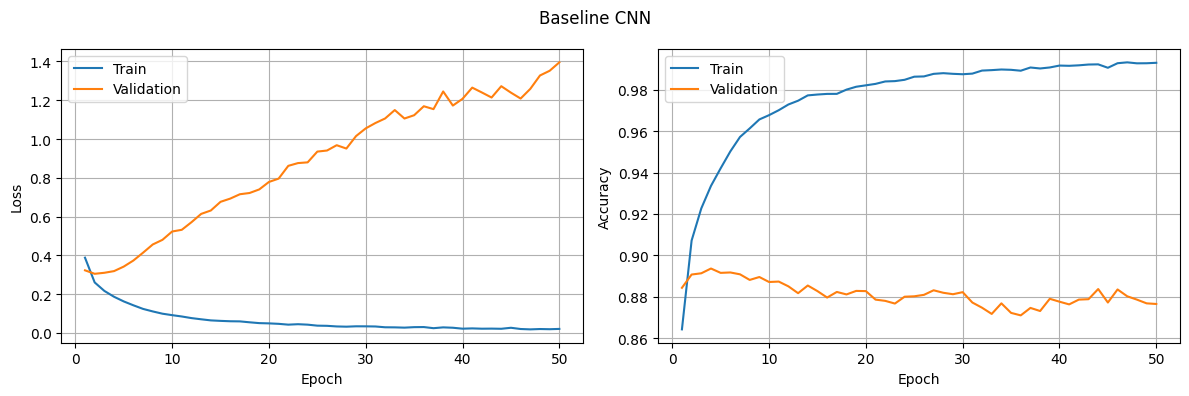

Train accuracy: 99.29%
Validation accuracy: 87.66%


In [6]:
def plot_training(training, title):
    values = training.history
    steps = np.arange(1, len(values['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, key, label in zip(axes, ['loss', 'accuracy'], ['Loss', 'Accuracy']):
        ax.plot(steps, values[key], label='Train')
        ax.plot(steps, values['val_' + key], label='Validation')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(label)
        ax.grid(True)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    print(f"Train accuracy: {values['accuracy'][-1]:.2%}")
    print(f"Validation accuracy: {values['val_accuracy'][-1]:.2%}")

plot_training(training, 'Baseline CNN')
loss_base, acc_base = model.evaluate(x_test, y_test, batch_size=batch_size, verbose=0)

### 5. Зменшення перенавчання
До моделі додано згорткові шари для розпізнавання ознак зображень. MaxPooling зменшує розмір карт ознак, а Dropout допомагає зменшити перенавчання. Перед навчанням перевірено, що кількість параметрів не перевищує кількість параметрів базової моделі.

In [ ]:
tf.keras.utils.set_random_seed(seed)
inputs = Input(shape=(28, 28, 1))
net = Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
net = Conv2D(32, (3, 3), activation='relu', padding='same')(net)

net = MaxPooling2D((2, 2))(net)
net = Dropout(0.25)(net)
net = Conv2D(64, (3, 3), activation='relu', padding='same')(net)
net = Conv2D(64, (3, 3), activation='relu', padding='same')(net)

net = MaxPooling2D((2, 2))(net)
net = Dropout(0.25)(net)
net = Flatten()(net)
net = Dense(128, activation='relu')(net)

net = Dropout(0.5)(net)
outputs = Dense(10, activation='softmax')(net)

model_reg = Model(inputs, outputs)
model_reg.summary()
params_reg = model_reg.count_params()
print('Baseline parameters:', params_base)
print('Regularized parameters:', params_reg)
print('Size requirement met:', params_reg <= params_base)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 467,818 (1.78 MB)

 Trainable params: 467,818 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

Baseline parameters: 3213002
Regularized parameters: 467818
Size requirement met: True


### 6. Навчання зміненої моделі
Навчання зупиняється, якщо помилка на валідаційній вибірці не зменшується протягом п’яти епох. Після цього відновлюються ваги моделі з епохи, у якій ця помилка була найменшою. Навчання триває не більше 50 епох.

Epoch 1/50
938/938 - 53s - 56ms/step - accuracy: 0.7981 - loss: 0.5597 - val_accuracy: 0.8740 - val_loss: 0.3466
Epoch 2/50
938/938 - 50s - 54ms/step - accuracy: 0.8717 - loss: 0.3561 - val_accuracy: 0.8932 - val_loss: 0.2902
Epoch 3/50
938/938 - 48s - 52ms/step - accuracy: 0.8888 - loss: 0.3068 - val_accuracy: 0.9070 - val_loss: 0.2474
Epoch 4/50
938/938 - 49s - 52ms/step - accuracy: 0.9012 - loss: 0.2737 - val_accuracy: 0.9094 - val_loss: 0.2372
Epoch 5/50
938/938 - 49s - 52ms/step - accuracy: 0.9085 - loss: 0.2507 - val_accuracy: 0.9160 - val_loss: 0.2330
Epoch 6/50
938/938 - 49s - 52ms/step - accuracy: 0.9147 - loss: 0.2353 - val_accuracy: 0.9206 - val_loss: 0.2145
Epoch 7/50
938/938 - 49s - 52ms/step - accuracy: 0.9184 - loss: 0.2203 - val_accuracy: 0.9171 - val_loss: 0.2175
Epoch 8/50
938/938 - 49s - 52ms/step - accuracy: 0.9230 - loss: 0.2090 - val_accuracy: 0.9192 - val_loss: 0.2246
Epoch 9/50
938/938 - 48s - 52ms/step - accuracy: 0.9264 - loss: 0.2021 - val_accuracy: 0.9215 - 

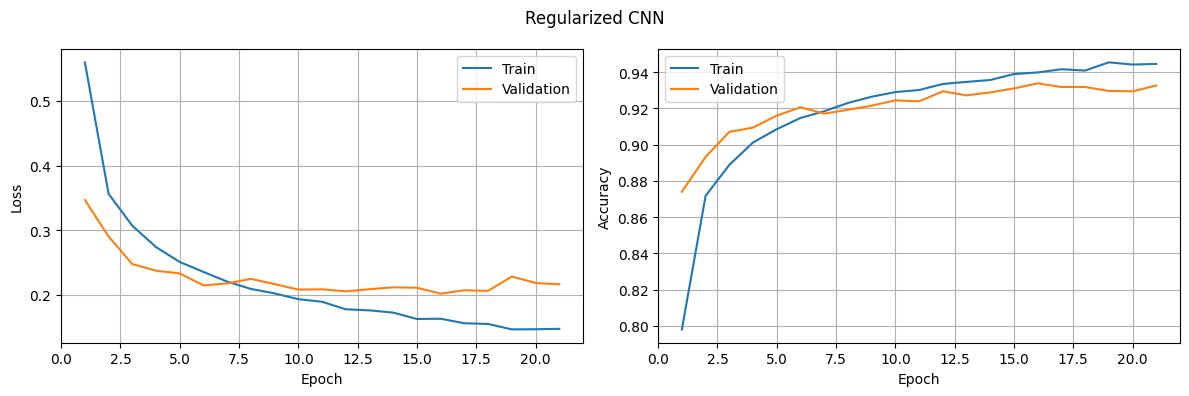

Train accuracy: 94.45%
Validation accuracy: 93.26%


In [ ]:
stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
model_reg.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
training_reg = model_reg.fit(x_train, y_train, epochs=epochs, batch_size=batch_size,
                             validation_data=(x_test, y_test), callbacks=[stop], verbose=2)
plot_training(training_reg, 'Regularized CNN')

### 7. Порівняння результатів
Оцінювання виконується для фактичних ваг обох моделей

In [9]:
loss_reg, acc_reg = model_reg.evaluate(x_test, y_test, batch_size=batch_size, verbose=0)
print(f'Baseline accuracy: {acc_base:.2%}')
print(f'Regularized accuracy: {acc_reg:.2%}')
print(f'Accuracy change: {(acc_reg - acc_base) * 100:+.2f} percentage points')
print('Accuracy above 91%:', acc_reg > 0.91)
print('Model not larger than baseline:', params_reg <= params_base)
print('Both requirements met:', acc_reg > 0.91 and params_reg <= params_base)

Baseline accuracy: 87.66%
Regularized accuracy: 93.38%
Accuracy change: +5.72 percentage points
Accuracy above 91%: True
Model not larger than baseline: True
Both requirements met: True


### 8. Відповіді на питання

**Що змінено?** Додано згорткові шари, MaxPooling і Dropout. MaxPooling зменшує розмір карт ознак і кількість параметрів перед шаром Dense. Dropout допомагає зменшити перенавчання. EarlyStopping зупиняє навчання, якщо помилка на валідації не зменшується протягом п’яти епох, і відновлює найкращі ваги.

**Які конфігурації перевірено?** Порівняно базову модель зі зміненою, до якої додано згорткові шари, MaxPooling, Dropout і ранню зупинку. Базова модель мала точність 87,66%, а змінена — 93,38%. Інші варіанти не перевірялися.

**Результат.** Точність зросла з 87,66% до 93,38%, тобто на 5,72 відсоткового пункта. Кількість параметрів зменшилася з `3 213 002` до `467 818`. 